# 1. Particle in a Box

## 1.1 Objective

To investigate the quantum mechanical behaviour of a particle in a one-dimensional box with walls of infinite potential.

## 1.2 Given

A particle of mass $m$ is confined between $x=0$ and $x=L$.

The potential energy is

\begin{equation}
    V(x)=
    \begin{cases}
    0, & 0<x<L\\
    \infty, & \text{outside the box}
    \end{cases}
\end{equation}

The wavefunction $\psi$ can be determined by solving the time independent Schrödinger equation:

\begin{equation}
    -\frac{\hbar^2}{2m}\frac{d^2\psi}{dx^2} = (E - V)\psi
\end{equation}

$\psi$ vanishes at the boundaries
$$
\psi(0)=\psi(L)=0
$$

In [2]:
# Importing libraries used in the notebook

import numpy as np
import matplotlib.pyplot as plt
from scipy import constants as const


In [3]:
#Box definitions

# Defining the box length
L = 1.0

# Generating points in the box
x = np.linspace(0, L, 500)

# Given
print(f"Box length: {L}")
print(f"Number of points: {len(x)}")
print(f"First position: {x[0]}")
print(f"Last position: {x[-1]}") # -1 to go in the reverse order

Box length: 1.0
Number of points: 500
First position: 0.0
Last position: 1.0


## 1.3 Theory and Code

### 1.3.1 Wave function $\psi$

The solution for the Schrödinger equation for a particle in a 1-dimensional box is given by

\begin{equation}
\psi_n(x) = \sqrt{\frac{2}{L}}\sin\left(\frac{n\pi x}{L}\right)
\end{equation}

where,

- $L$: box length,
- $x$: position,
- $n$: quantum number,
- $\psi_n(x)$: wave function for n.

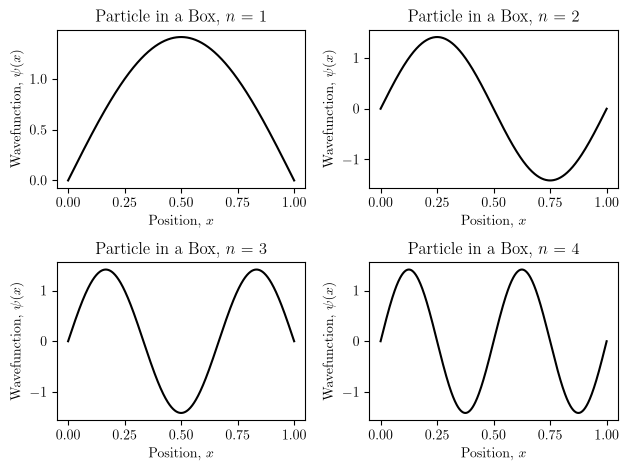

In [11]:
# Creating the figure and axes (2 rows and 2 columns as subplots)
fig, axes = plt.subplots(2, 2)

# Rendering in LaTeX
plt.rcParams.update({"text.usetex": True, "font.family": "serif"})

# Loop to check for n = 1, 2, 3, 4
    # enumerate() gives two values: the number (n) and the subplot itself (ax), eg: 1 subplot-1, 2 subplot-2, etc.
    # axes is a collection of subplots, and axes.flat gives an iterable version.
    # start = 1, as it would usually start from 0.

for n, ax in enumerate(axes.flat, start = 1):

    # Wave function
    psi = np.sqrt(2/L)*np.sin((n*np.pi*x)/L)

    # Plotting the points
    ax.plot(x, psi, color = 'k')

    # Setting title and labels for each subplot, not the whole figure.
    ax.set_xlabel("Position, $x$")
    ax.set_ylabel(r"Wavefunction, $\psi(x)$")
    ax.set_title(f"Particle in a Box, $n$ = {n}")

plt.tight_layout()
plt.show()

#### 1.3.1.1 Result
The number of inflections of the resulting sine wave is zero for $n$ = 1 and increases by 1 with each value of $n$.

### 1.3.2 Energy of the particle

The energy $E$ of the particle can be solved to be

\begin{equation}
E = \frac{n^2h^2}{8l^2m}
\end{equation}

It is constant and only depends on the quantum number, $n$, i.e., it is quantised.


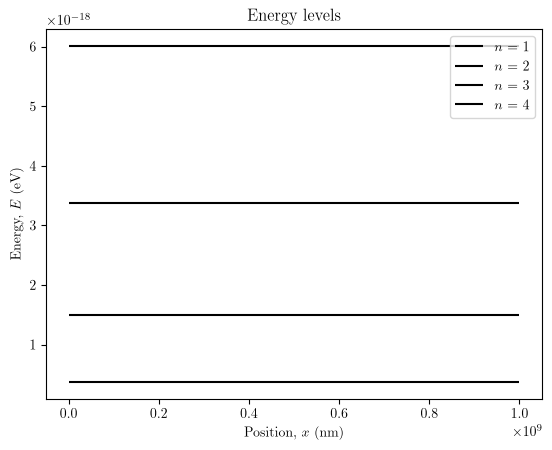

In [13]:
# Start the plot
plt.figure()

# Rendering in LaTeX
plt.rcParams.update({"text.usetex": True, "font.family": "serif"})

# Looping through the values of n
# Using scipy.constants to obtain the values of h and m
for n in range(1,5):
    energy = (n**2*const.h**2)/(8*L**2*const.m_e)
    energy_eV = energy/const.e
    plt.hlines(energy_eV, 0, L*1e9, label = f"$n$ = {n}", color = 'k')

# Labels
plt.xlabel("Position, $x$ (nm)")
plt.ylabel("Energy, $E$ (eV)")
plt.title("Energy levels")
plt.legend()
plt.show()


#### 1.3.2.1 Result
- The ground state ($n$ = 1) has a non-zero energy, indicating that the particle cannot have zero energy even in its lowest state. This is referred to as the **_zero point energy_**.
- As the quantum number ($n$) increases, the gap between each successive energy level also increases in accordance with the relationship $E_n \propto n^2$

### 1.3.3 Probability density

The wavefunction $\psi$ does not have any physical significance, but its square $|\psi|^2$ represents the probability density of the particle in space, given by:

\begin{equation}
|\psi|^2 = \frac{2}{L}sin^2\left(\frac{n\pi x}{L}\right)
\end{equation}

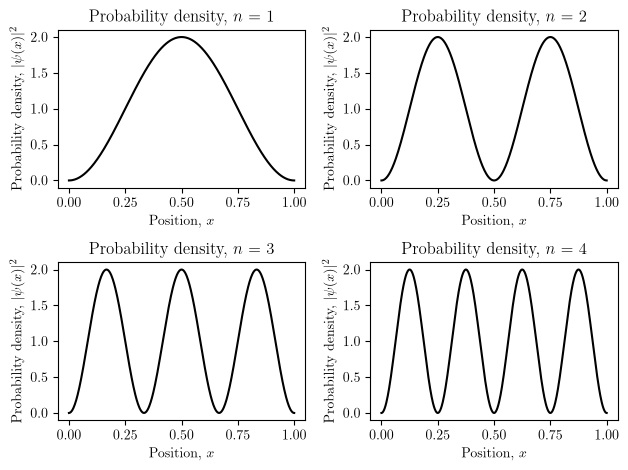

In [16]:
fig, axes = plt.subplots(2, 2)

plt.rcParams.update({"text.usetex": True, "font.family": "serif"})

for n, ax in enumerate(axes.flat, start = 1):

    psi_sq = (2/L)*(np.sin((n*np.pi*x)/L))**2

    ax.plot(x, psi_sq, color = 'k')
    ax.set_xlabel("Position, $x$")
    ax.set_ylabel(r"Probability density, $|\psi(x)|^2$")
    ax.set_title(f"Probability density, $n$ = {n}")

plt.tight_layout()
plt.show()

#### 1.3.3.1 Result

- As opposed to $\psi$, the graphs for ${\psi}^2$ display only positive values, which makes it a better mode to express probability. Each node represents a point where the electron is not found.

- The crests and troughs in the graphs come closer with each successive value for $n$. At sufficiently large values of $n$, the variations in probability become undetectable, thus achieving uniformity. This is the crossover from quantum to classical mechanics for macroscopic bodies, and is referred to as **_Bohr's correspondence principle_**.

### 1.3.4 Orthonormality

Consider an electron possessing quantum number $n_i$. It must be found somewhere in space, and hence, the wavefunction is **_normalised_**, i.e., the probability $|\psi|_i ^2$must be equal to 1.

However, if we consider two different quantum numbers $n_i$ and $n_j,$ the corresponding wave numbers $\psi_i$ and $\psi_j$ are **_orthogonal_** to each other. This means that the electron must be found completely in one state and not the other (An electron cannot be in two different energy levels at once).

\begin{equation}
\int_{-\infty}^{\infty} \psi_i ^* \psi_j \,dx = \delta_{ij}
\end{equation}

The symbol $\delta_{ij}$ is referred to as the **_Kronecker delta_**, and its values are:

\begin{equation}
    \delta_{ij} =
    \begin{cases}
    1, & i=j\\
    0, & i\neq j
    \end{cases}
\end{equation}

This property of wavefunctions is called **_orthonormality_**
